## 1. Imports & Config

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error


from sales_forecast_utils import (
    load_and_aggregate, add_features, get_feature_cols, recursive_forecast,
)

%matplotlib inline

DATA_PATH = "C:/projects/sales_forecasting/Superstore.csv"   
TEST_SIZE_WEEKS = 13           
FORECAST_HORIZON_WEEKS = 12


In [2]:
raw, weekly = load_and_aggregate(DATA_PATH)

print(raw.shape)
raw.head()


(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   str           
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [4]:
raw.isnull().sum()


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

## 3. Exploratory Data Analysis
This dataset is **transaction-level** (one row per order line item), so we first look at it raw, then aggregate to a time series for forecasting.

In [5]:
print("Date range:", raw["Order Date"].min(), "to", raw["Order Date"].max())
print("Unique order dates:", raw["Order Date"].nunique())
print("Unique customers:", raw["Customer ID"].nunique())
print("Categories:", raw["Category"].unique())


Date range: 2014-01-03 00:00:00 to 2017-12-30 00:00:00
Unique order dates: 1237
Unique customers: 793
Categories: <ArrowStringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str


In [6]:
raw["Sales"].describe()


count     9994.000000
mean       229.858001
std        623.245101
min          0.444000
25%         17.280000
50%         54.490000
75%        209.940000
max      22638.480000
Name: Sales, dtype: float64

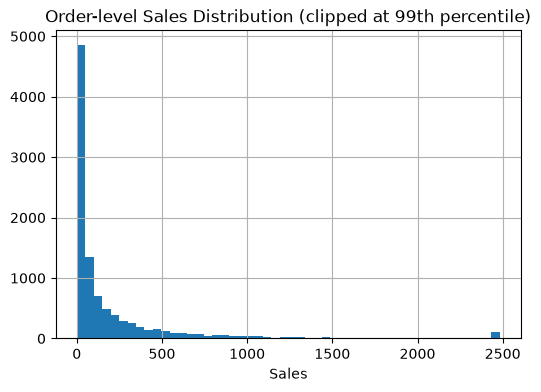

In [7]:
plt.figure(figsize=(6,4))
raw["Sales"].clip(upper=raw["Sales"].quantile(0.99)).hist(bins=50)
plt.title("Order-level Sales Distribution (clipped at 99th percentile)")
plt.xlabel("Sales")
plt.show()


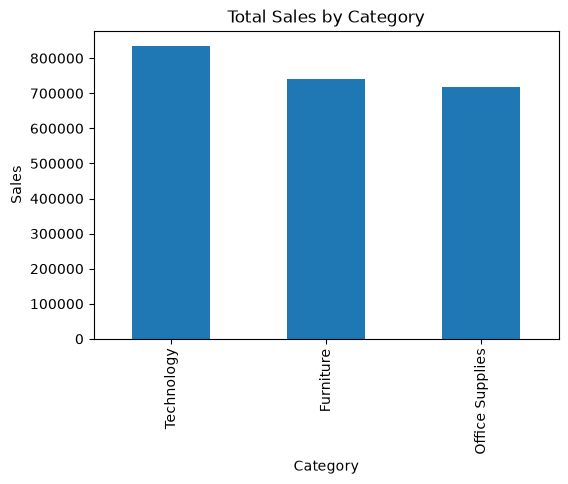

In [8]:
category_sales = raw.groupby("Category")["Sales"].sum().sort_values(ascending=False)
category_sales.plot(kind="bar", figsize=(6,4), title="Total Sales by Category")
plt.ylabel("Sales")
plt.show()


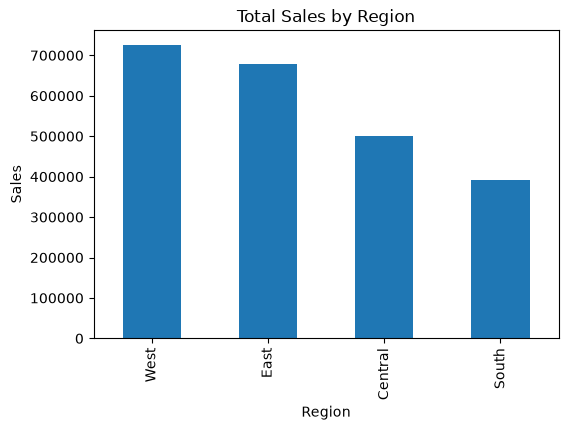

In [9]:
region_sales = raw.groupby("Region")["Sales"].sum().sort_values(ascending=False)
region_sales.plot(kind="bar", figsize=(6,4), title="Total Sales by Region")
plt.ylabel("Sales")
plt.show()


### Why weekly, not daily? Proof, not assumption
Before picking a granularity, compare how *noisy* the series is at each level. A lower coefficient of variation (std / mean) means a more learnable, less erratic signal.

In [10]:
daily_check = raw.groupby("Order Date")["Sales"].sum()
full_idx = pd.date_range(daily_check.index.min(), daily_check.index.max(), freq="D")
daily_check = daily_check.reindex(full_idx).fillna(0)

print("DAILY   -> mean: {:.0f}  std: {:.0f}  CoV: {:.2f}  %zero days: {:.1f}%".format(
    daily_check.mean(), daily_check.std(), daily_check.std()/daily_check.mean(),
    (daily_check == 0).mean()*100))
print("WEEKLY  -> mean: {:.0f}  std: {:.0f}  CoV: {:.2f}".format(
    weekly["sales"].mean(), weekly["sales"].std(), weekly["sales"].std()/weekly["sales"].mean()))


DAILY   -> mean: 1576  std: 2226  CoV: 1.41  %zero days: 15.2%
WEEKLY  -> mean: 10991  std: 7589  CoV: 0.69


**Observation:** the daily series has a coefficient of variation close to 1 (std roughly equal to the mean) and ~15% zero-sales days - very noisy. Weekly aggregation smooths much of this out, which is why every model benchmarked later performs meaningfully better at weekly granularity (see Section 10).

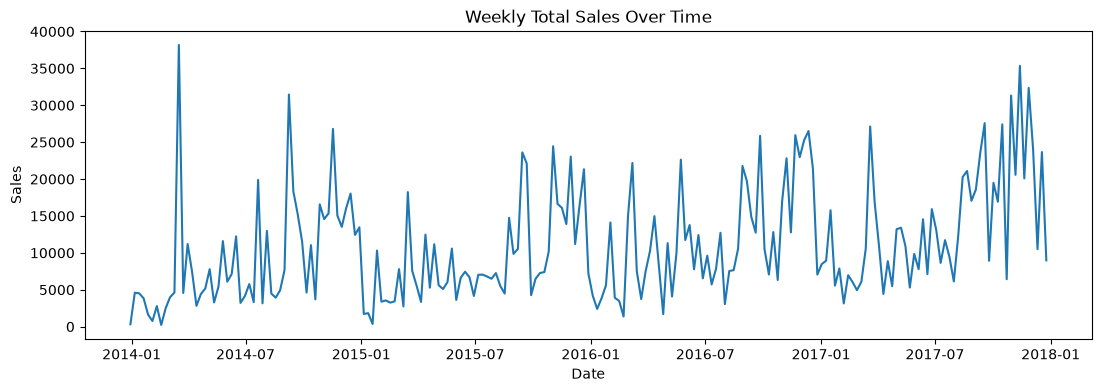

In [11]:
plt.figure(figsize=(13,4))
plt.plot(weekly["date"], weekly["sales"])
plt.title("Weekly Total Sales Over Time")
plt.xlabel("Date"); plt.ylabel("Sales")
plt.show()


## 4. Feature Engineering
`add_features` (from `sales_forecast_utils.py`) builds:
- **Calendar features**: month, quarter, week of year, month-start/end flags
- **US holiday flag**: whether the week contains a federal holiday (via pandas' built-in calendar)
- **Fourier terms**: smooth sin/cos curves over the year, for seasonality beyond blunt month/quarter flags
- **Lag & rolling features**: sales 1/4/8/12 weeks ago, rolling mean/std, and an EWM (exponentially-weighted moving average, which weights recent weeks more heavily)
- **External features**: last week's order count, quantity, and average discount - previously-unused columns in the raw data that carry real signal

All lag/rolling/external features are shifted so a given week's features never use that same week's own values (avoiding data leakage).

In [12]:
featured = add_features(weekly).dropna().reset_index(drop=True)
feature_cols = get_feature_cols(featured)

print("Feature columns:", feature_cols)
featured.head()


Feature columns: ['month', 'quarter', 'week_of_year', 'is_month_start', 'is_month_end', 'contains_holiday', 'fourier_sin_1', 'fourier_cos_1', 'fourier_sin_2', 'fourier_cos_2', 'lag_1', 'lag_4', 'lag_8', 'lag_12', 'rolling_mean_4', 'rolling_std_4', 'ewm_mean_4', 'rolling_mean_8', 'rolling_std_8', 'ewm_mean_8', 'rolling_mean_12', 'rolling_std_12', 'ewm_mean_12', 'order_count_lag1', 'quantity_lag1', 'avg_discount_lag1']


,date,sales,month,quarter,week_of_year,is_month_start,is_month_end,contains_holiday,fourier_sin_1,fourier_cos_1,...,ewm_mean_4,rolling_mean_8,rolling_std_8,ewm_mean_8,rolling_mean_12,rolling_std_12,ewm_mean_12,order_count_lag1,quantity_lag1,avg_discount_lag1
0,2014-03-24,4554.623,3,1,13,0,0,0,0.989794,0.142508,...,17389.572422,6832.311250,12752.363411,11226.226927,5661.135083,10372.950215,9151.719007,18.0,220.0,0.170393
1,2014-03-31,11193.080,3,1,14,0,1,0,0.999745,0.022576,...,12248.878550,7196.350375,12623.962265,9684.896972,6013.683333,10246.185110,8353.488499,17.0,97.0,0.092063
2,2014-04-07,7445.859,4,2,15,0,0,0,0.995218,-0.097683,...,11826.227923,8500.874375,12400.713527,10030.288500,6563.142333,10339.821429,8836.980269,25.0,194.0,0.102045
3,2014-04-14,2810.244,4,2,16,0,0,0,0.976277,-0.216527,...,10073.256133,9084.095000,12201.337344,9442.415300,6807.870000,10321.524241,8603.943641,17.0,163.0,0.107426
4,2014-04-21,4409.654,4,2,17,0,0,0,0.943196,-0.332235,...,7167.231458,9406.971000,11965.376805,7941.684650,6721.858000,10352.736320,7646.489095,8.0,71.0,0.076786


## 5. Train / Test Split
Time series data must be split **chronologically**, never shuffled randomly, or the model would learn from the future to predict the past.

In [13]:
cutoff = featured["date"].max() - pd.Timedelta(weeks=TEST_SIZE_WEEKS)
train = featured[featured["date"] <= cutoff]
test = featured[featured["date"] > cutoff]

X_train, y_train = train[feature_cols], train["sales"]
X_test, y_test = test[feature_cols], test["sales"]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train dates:", train["date"].min().date(), "to", train["date"].max().date())
print("Test dates:", test["date"].min().date(), "to", test["date"].max().date())


Train: (184, 26) Test: (13, 26)
Train dates: 2014-03-24 to 2017-09-25
Test dates: 2017-10-02 to 2017-12-25


## 6. Model Benchmarking (with time-series cross-validation)
Rather than trusting default hyperparameters on a single holdout, we tune Random Forest and Gradient Boosting using `TimeSeriesSplit` (cross-validation that always trains on the past and validates on the future - never shuffled) combined with `GridSearchCV`. `xgboost`/`lightgbm` are included with default settings if installed; otherwise they're skipped automatically.

In [14]:
tscv = TimeSeriesSplit(n_splits=4)

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid={"n_estimators": [200, 400], "max_depth": [6, 10, None]},
    cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
rf_grid.fit(X_train, y_train)
print("Random Forest best params:", rf_grid.best_params_)

gbr_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid={"n_estimators": [200, 400], "learning_rate": [0.03, 0.05, 0.1], "max_depth": [3, 4]},
    cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
gbr_grid.fit(X_train, y_train)
print("Gradient Boosting best params:", gbr_grid.best_params_)


Random Forest best params: {'max_depth': 6, 'n_estimators': 400}
Gradient Boosting best params: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200}


In [15]:
candidates = {
    "Linear Regression": LinearRegression().fit(X_train, y_train),
    "Ridge Regression": Ridge(alpha=1.0).fit(X_train, y_train),
    "Random Forest (tuned)": rf_grid.best_estimator_,
    "Gradient Boosting (tuned)": gbr_grid.best_estimator_,
}

try:
    import xgboost as xgb
    candidates["XGBoost"] = xgb.XGBRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=4, random_state=42
    ).fit(X_train, y_train)
except ImportError:
    print("xgboost not installed - run: pip install xgboost")

try:
    import lightgbm as lgb
    candidates["LightGBM"] = lgb.LGBMRegressor(
        n_estimators=400, learning_rate=0.05, max_depth=4, random_state=42, verbose=-1
    ).fit(X_train, y_train)
except ImportError:
    print("lightgbm not installed - run: pip install lightgbm")

print("Models benchmarked:", list(candidates.keys()))


xgboost not installed - run: pip install xgboost
lightgbm not installed - run: pip install lightgbm
Models benchmarked: ['Linear Regression', 'Ridge Regression', 'Random Forest (tuned)', 'Gradient Boosting (tuned)']


In [16]:
results = {}

def evaluate(name, preds):
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    rel_rmse = rmse / y_test.mean() * 100
    results[name] = {"MAE": mae, "RMSE": rmse, "RMSE_pct_of_mean": rel_rmse}
    print(f"{name:28s} -> MAE: {mae:9.2f}  RMSE: {rmse:9.2f}  RMSE/mean: {rel_rmse:5.1f}%")

# Baselines first, for context
evaluate("Naive (lag_1 week)", X_test["lag_1"])
evaluate("Moving Avg (4wk)", X_test["rolling_mean_4"])

for name, model in candidates.items():
    preds = model.predict(X_test)
    evaluate(name, preds)


Naive (lag_1 week)           -> MAE:  13250.09  RMSE:  14269.32  RMSE/mean:  66.9%
Moving Avg (4wk)             -> MAE:   7443.38  RMSE:   9446.99  RMSE/mean:  44.3%
Linear Regression            -> MAE:   8231.50  RMSE:   9405.04  RMSE/mean:  44.1%
Ridge Regression             -> MAE:   8176.12  RMSE:   9393.63  RMSE/mean:  44.1%
Random Forest (tuned)        -> MAE:   8029.15  RMSE:   9678.82  RMSE/mean:  45.4%
Gradient Boosting (tuned)    -> MAE:   7478.43  RMSE:   9338.91  RMSE/mean:  43.8%


In [17]:
results_df = pd.DataFrame(results).T.sort_values("RMSE")
results_df


,MAE,RMSE,RMSE_pct_of_mean
Gradient Boosting (tuned),7478.430890,9338.910581,43.816863
Ridge Regression,8176.122832,9393.630477,44.073601
Linear Regression,8231.498914,9405.041296,44.127139
Moving Avg (4wk),7443.383331,9446.989636,44.323955
Random Forest (tuned),8029.150394,9678.819106,45.411667
Naive (lag_1 week),13250.090508,14269.320130,66.949656


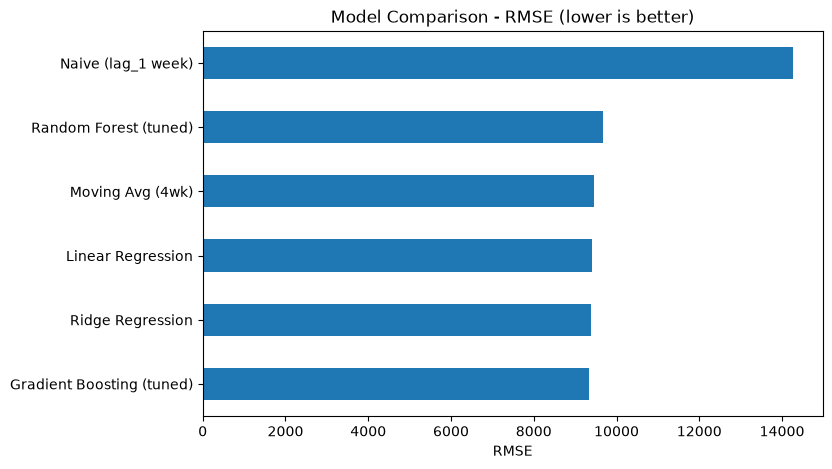

Best model on this holdout set: Gradient Boosting (tuned)


In [18]:
results_df["RMSE"].sort_values().plot(kind="barh", figsize=(8,5), title="Model Comparison - RMSE (lower is better)")
plt.xlabel("RMSE")
plt.show()

best_name = results_df["RMSE"].idxmin()
print("Best model on this holdout set:", best_name)


**Note:** even the winning model's RMSE is a meaningful fraction of average weekly sales - treat small RMSE gaps between top models as within noise, not a decisive win. Re-running with a different holdout window is a good sanity check before trusting the ranking.

## 7. Feature Importance (for tree-based winner)

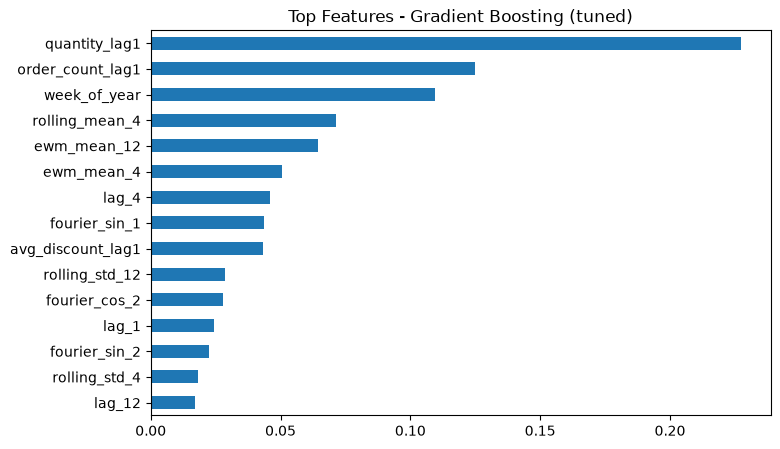

In [19]:
best_model = candidates.get(best_name)

if best_model is not None and hasattr(best_model, "feature_importances_"):
    importance = pd.Series(best_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
    importance.head(15).sort_values().plot(kind="barh", figsize=(8,5), title=f"Top Features - {best_name}")
    plt.show()
    importance.head(10)
else:
    print(f"{best_name} has no feature_importances_ attribute (likely a linear or baseline model).")


## 8. Retrain Best Model on Full Data & Save

In [20]:
best_model_class = type(candidates[best_name])
best_params = candidates[best_name].get_params()

X_full, y_full = featured[feature_cols], featured["sales"]
final_model = best_model_class(**best_params)
final_model.fit(X_full, y_full)

joblib.dump(final_model, "final_model.pkl")
print(f"Final model ({best_name}) retrained on full data and saved to final_model.pkl")


Final model (Gradient Boosting (tuned)) retrained on full data and saved to final_model.pkl


## 9. Forecast Future Sales
Since future weeks don't have real lag/rolling values yet, we forecast **recursively**: predict one week, append it to history, then use it to compute the next week's lag features, and so on. External-signal features (order count, quantity, discount) are carried forward using their last known value, since future values of those aren't knowable in advance either. `recursive_forecast` is the same shared function `app.py` calls.

In [21]:
future_df = recursive_forecast(final_model, weekly, feature_cols, FORECAST_HORIZON_WEEKS)
future_df.to_csv("future_forecast.csv", index=False)
future_df.head(10)


,date,sales
0,2018-01-01,10386.596970
1,2018-01-08,10817.732414
2,2018-01-15,13265.885599
3,2018-01-22,12414.429186
4,2018-01-29,12180.951196
5,2018-02-05,12513.599439
6,2018-02-12,12012.414835
7,2018-02-19,11907.464903
8,2018-02-26,11826.770860
9,2018-03-05,11183.132015


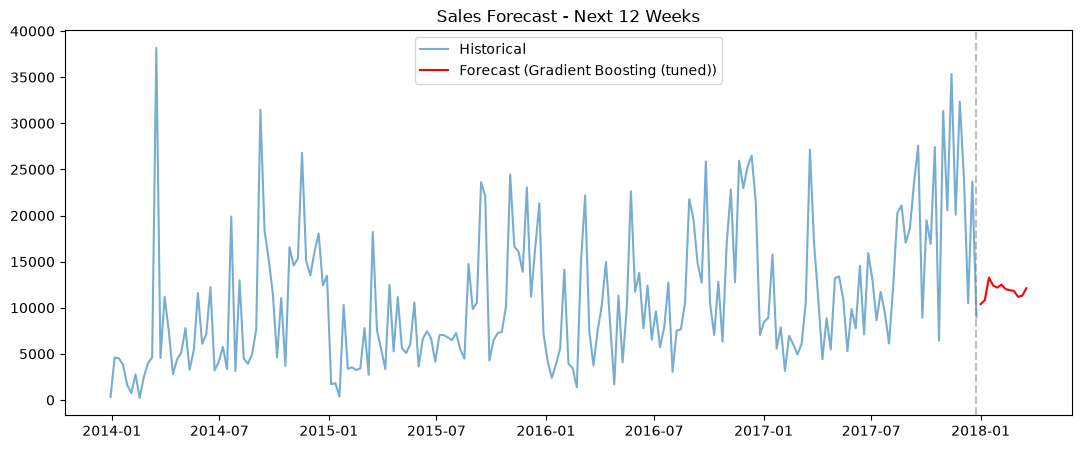

In [22]:
plt.figure(figsize=(13,5))
plt.plot(weekly["date"], weekly["sales"], label="Historical", alpha=0.6)
plt.plot(future_df["date"], future_df["sales"], label=f"Forecast ({best_name})", color="red")
plt.axvline(weekly["date"].max(), linestyle="--", color="gray", alpha=0.5)
plt.legend()
plt.title(f"Sales Forecast - Next {FORECAST_HORIZON_WEEKS} Weeks")
plt.show()


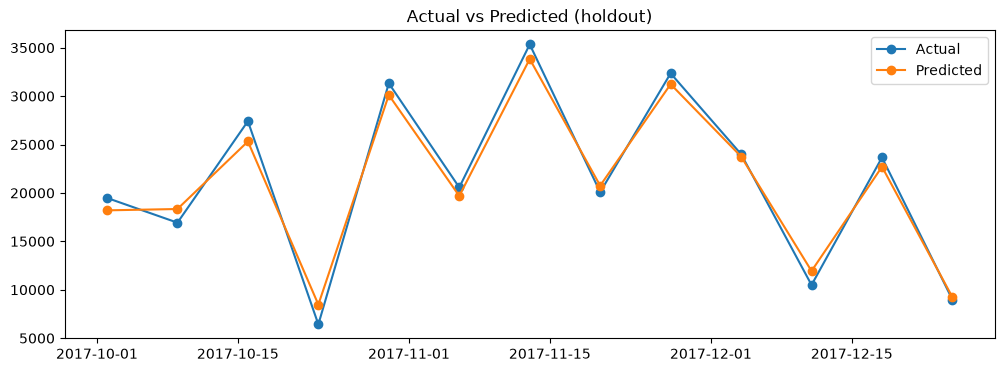

In [23]:
preds = final_model.predict(X_test)

plt.figure(figsize=(12,4))
plt.plot(test["date"], y_test.values, label="Actual", marker="o")
plt.plot(test["date"], preds, label="Predicted", marker="o")
plt.legend(); plt.title("Actual vs Predicted (holdout)")
plt.show()

Mean error (bias): 267.79952804608416


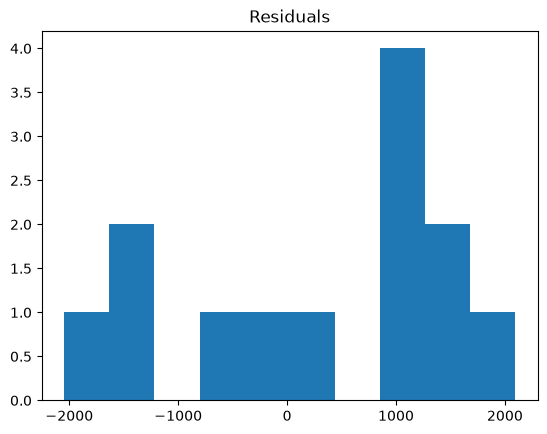

In [24]:
residuals = y_test.values - preds
print("Mean error (bias):", residuals.mean())   # should be near 0
plt.hist(residuals, bins=10); plt.title("Residuals"); plt.show()

In [25]:
test_eval = test[["date"]].copy()
test_eval["actual"] = y_test.values
test_eval["pred"] = preds
test_eval["error"] = test_eval["actual"] - test_eval["pred"]
print(test_eval)

          date      actual          pred        error
184 2017-10-02  19484.3160  18202.542784  1281.773216
185 2017-10-09  16929.3750  18340.565920 -1411.190920
186 2017-10-16  27411.7552  25317.615892  2094.139308
187 2017-10-23   6423.3530   8469.131677 -2045.778677
188 2017-10-30  31325.5710  30117.731760  1207.839240
189 2017-11-06  20571.8720  19691.100981   880.771019
190 2017-11-13  35344.4230  33832.373890  1512.049110
191 2017-11-20  20087.2490  20751.701020  -664.452020
192 2017-11-27  32354.5700  31233.454484  1121.115516
193 2017-12-04  24006.9580  23763.560780   243.397220
194 2017-12-11  10495.9630  11937.063573 -1441.100573
195 2017-12-18  23662.3640  22705.262205   957.101795
196 2017-12-25   8977.8318   9232.102170  -254.270370
